In [42]:

from google.colab import files

uploaded = files.upload()


Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data (1).csv


In [43]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("healthcare-dataset-stroke-data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Dataset shape: (5110, 12)

Column names:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [44]:

print("Dataset dimensions:", df.shape)

print("\nColumn names and data types:")
df.info()

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

print("\nNumber of duplicate rows:", df.duplicated().sum())


Dataset dimensions: (5110, 12)

Column names and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

First five records:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1



Last five records:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0



Number of duplicate rows: 0


In [45]:

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage (%)": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_summary.sort_values(
    by="Missing Values", ascending=False
))


,Missing Values,Missing Percentage (%)
bmi,201,3.93
id,0,0.00
age,0,0.00
gender,0,0.00
hypertension,0,0.00
heart_disease,0,0.00
work_type,0,0.00
ever_married,0,0.00
Residence_type,0,0.00
avg_glucose_level,0,0.00


In [46]:

print("Stroke target counts:")
display(df["stroke"].value_counts().sort_index())

print("\nStroke target percentages:")
display(
    (df["stroke"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nTarget variable unique values:")
print(df["stroke"].unique())


Stroke target counts:


,count
stroke,
0,4861
1,249



Stroke target percentages:


,proportion
stroke,
0,95.13
1,4.87



Target variable unique values:
[1 0]


In [47]:

categorical_columns = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

print("\nNumerical summary:")
display(df.describe().T)



gender:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

ever_married:
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

work_type:
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Residence_type:
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

smoking_status:
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


In [48]:

print("INITIAL DATASET AUDIT")
print("-" * 35)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Exact duplicate rows:", df.duplicated().sum())
print("Total missing cells:", df.isnull().sum().sum())
print("Missing BMI values:", df["bmi"].isnull().sum())
print("Unique target values:", sorted(df["stroke"].dropna().unique()))
print("Target class counts:")
print(df["stroke"].value_counts().sort_index())


INITIAL DATASET AUDIT
-----------------------------------
Rows: 5110
Columns: 12
Exact duplicate rows: 0
Total missing cells: 201
Missing BMI values: 201
Unique target values: [np.int64(0), np.int64(1)]
Target class counts:
stroke
0    4861
1     249
Name: count, dtype: int64


EDA


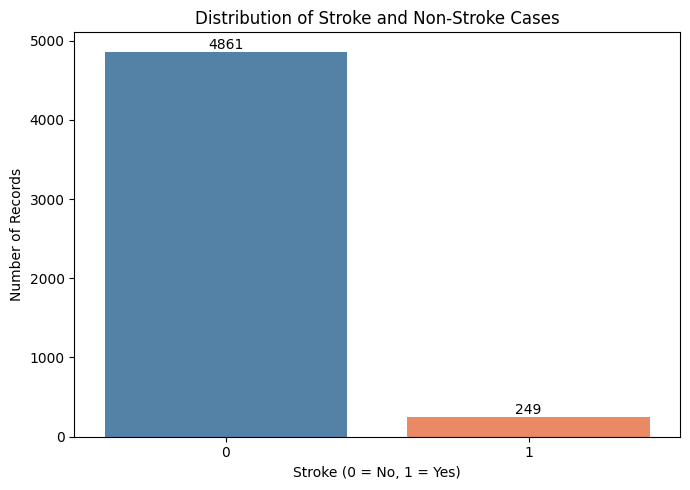

In [49]:

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="stroke",
    hue="stroke",
    palette={0: "steelblue", 1: "coral"},
    legend=False
)

plt.title("Distribution of Stroke and Non-Stroke Cases")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height())}",
        (bar.get_x() + bar.get_width() / 2,
         bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.tight_layout()
plt.savefig("stroke_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()



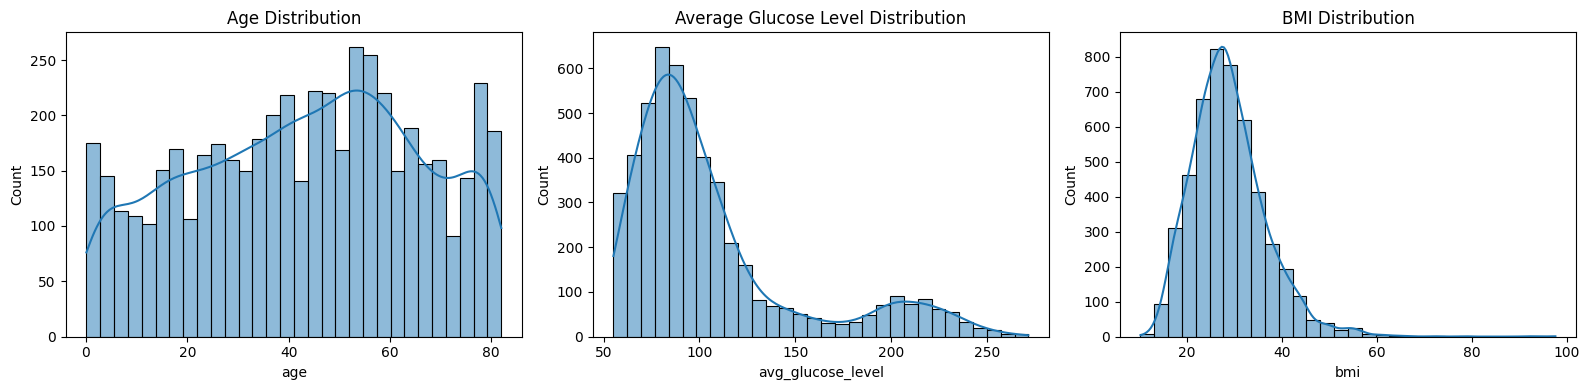

In [50]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(
    data=df, x="age", bins=30, kde=True, ax=axes[0]
)
axes[0].set_title("Age Distribution")

sns.histplot(
    data=df, x="avg_glucose_level", bins=30,
    kde=True, ax=axes[1]
)
axes[1].set_title("Average Glucose Level Distribution")

sns.histplot(
    data=df, x="bmi", bins=30,
    kde=True, ax=axes[2]
)
axes[2].set_title("BMI Distribution")

plt.tight_layout()
plt.tight_layout()
plt.savefig("stroke_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


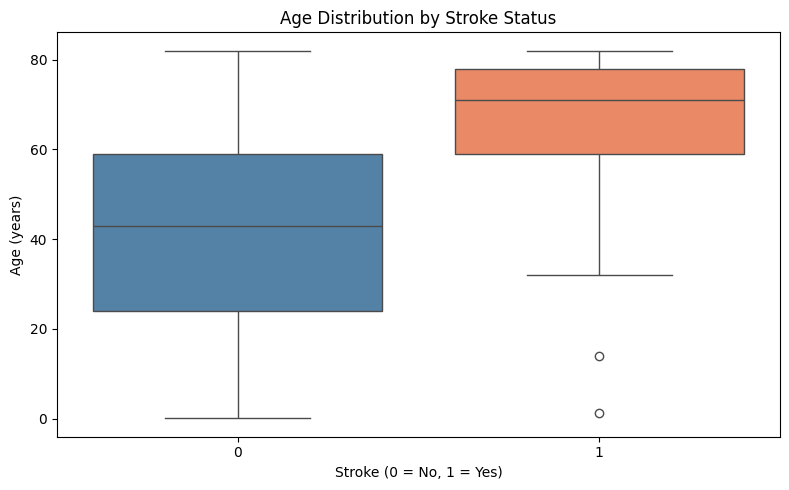

In [51]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="stroke",
    y="age",
    hue="stroke",
    palette={0: "steelblue", 1: "coral"},
    legend=False
)

plt.title("Age Distribution by Stroke Status")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Age (years)")
plt.tight_layout()
plt.tight_layout()
plt.savefig("stroke_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


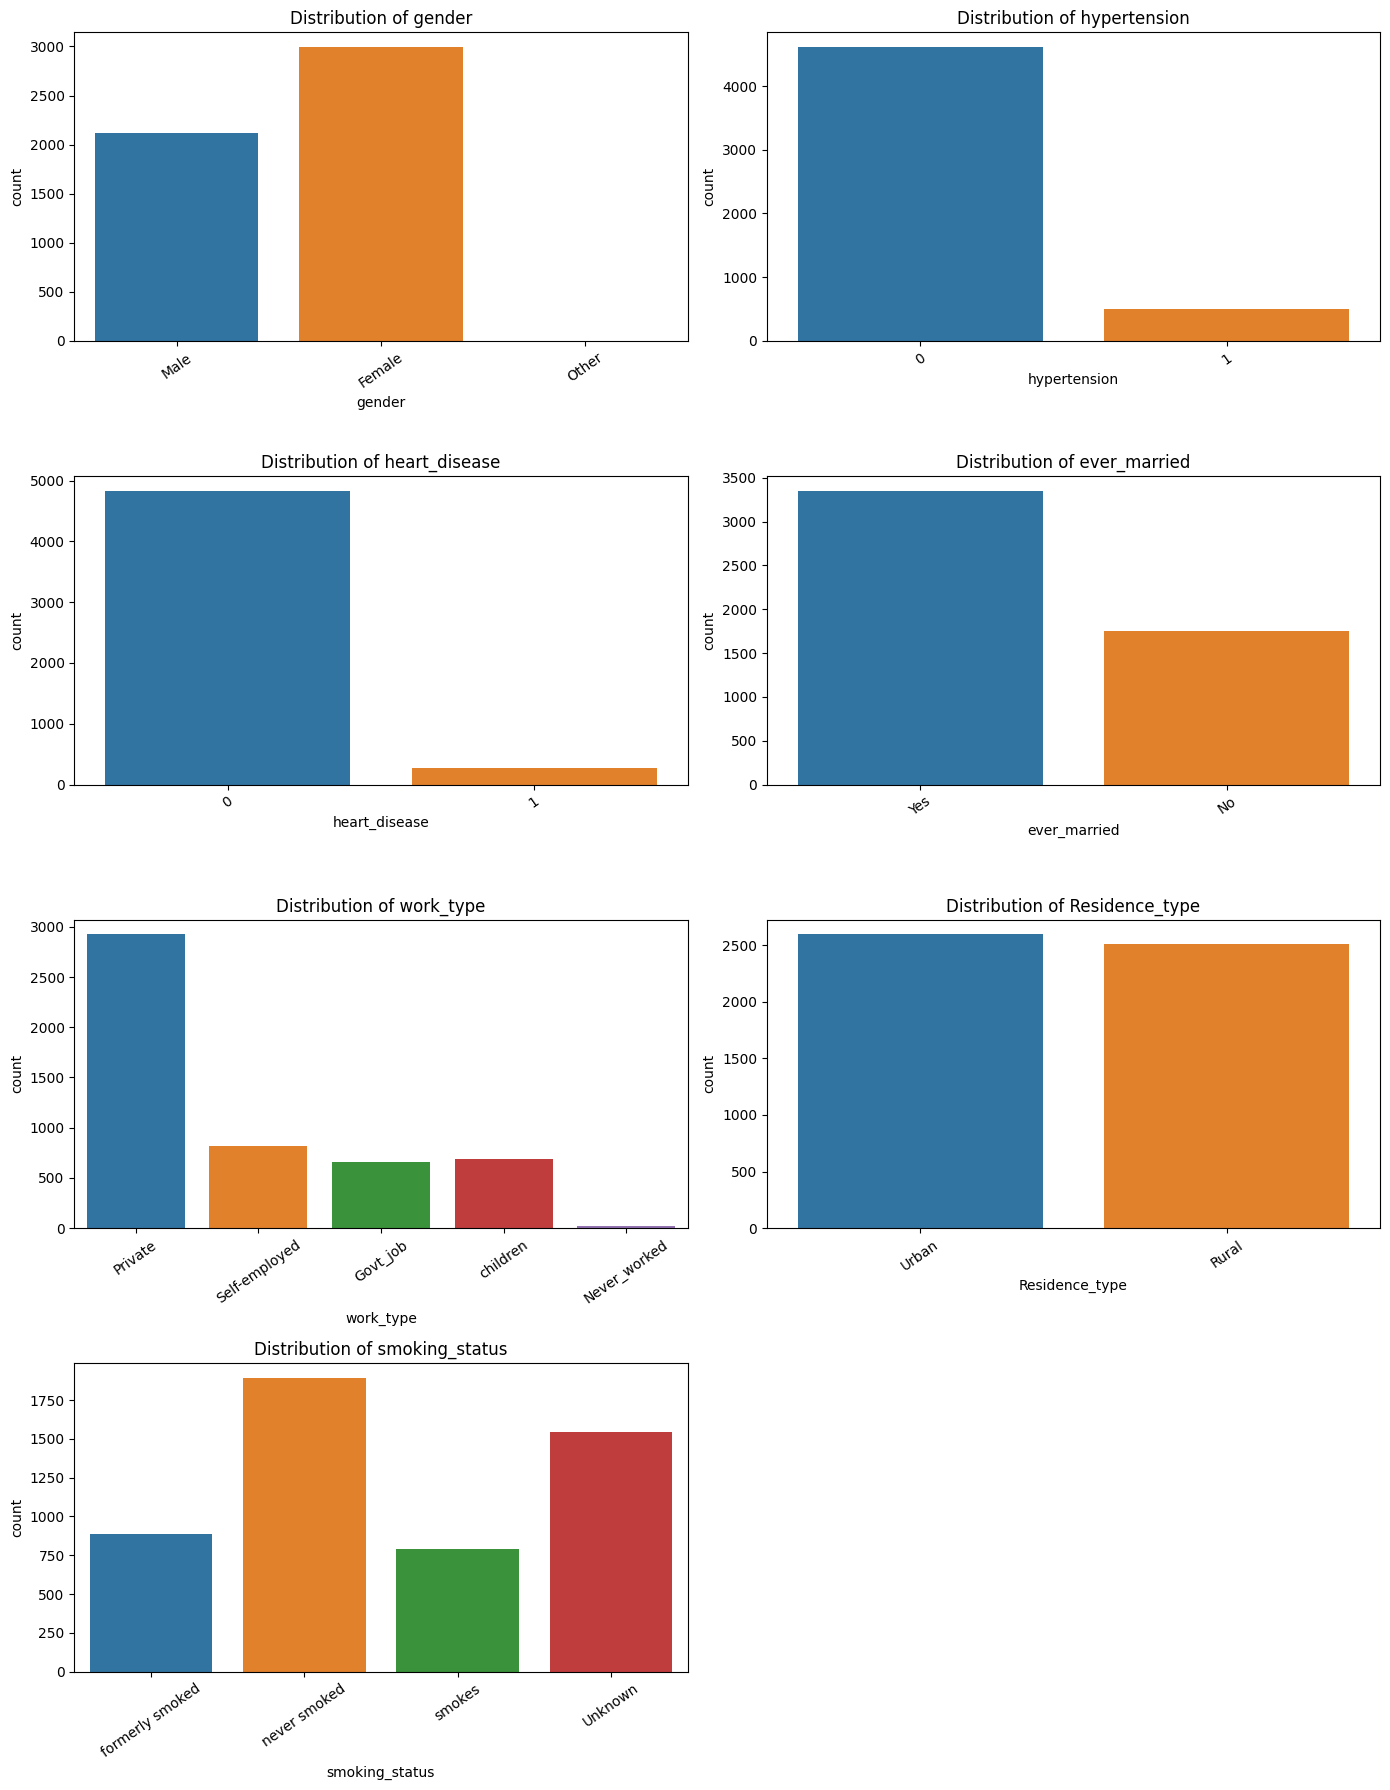

In [52]:

categorical_columns = [
    "gender",
    "hypertension",
    "heart_disease",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, column in enumerate(categorical_columns):
    sns.countplot(
        data=df,
        x=column,
        hue=column,
        ax=axes[i],
        legend=False
    )
    axes[i].set_title(f"Distribution of {column}")
    axes[i].tick_params(axis="x", rotation=35)

axes[-1].set_visible(False)
plt.tight_layout()
plt.tight_layout()
plt.savefig("stroke_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()



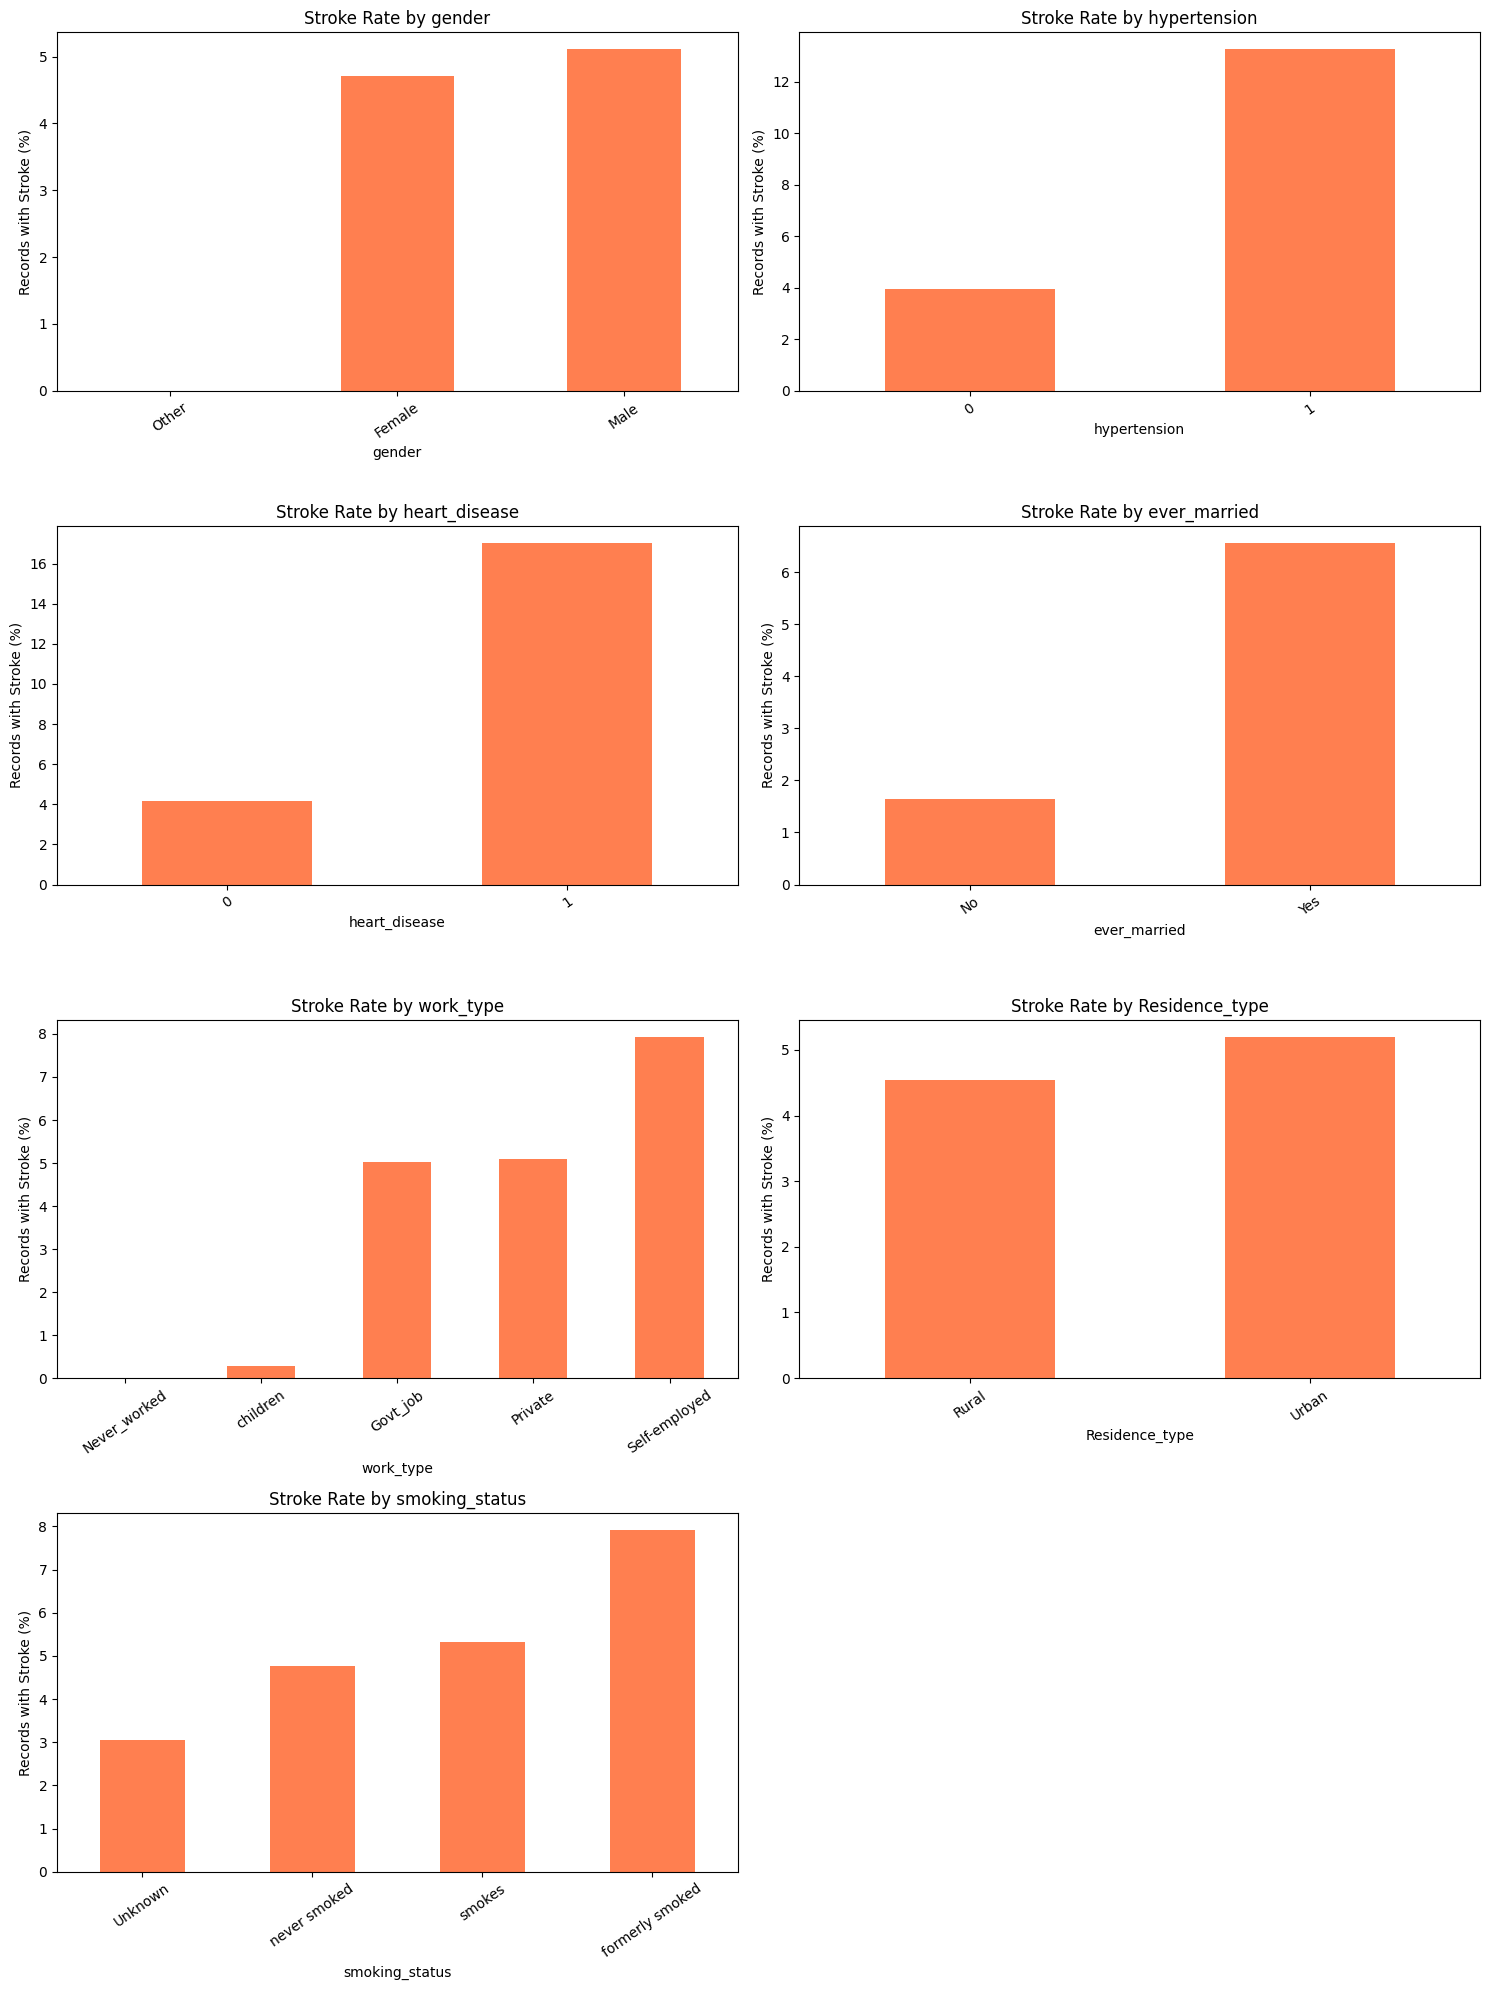

In [53]:

categorical_features = [
    "gender",
    "hypertension",
    "heart_disease",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 20))
axes = axes.flatten()

for i, column in enumerate(categorical_features):
    stroke_rate = pd.crosstab(
        df[column],
        df["stroke"],
        normalize="index"
    ) * 100

    if 1 not in stroke_rate.columns:
        stroke_rate[1] = 0

    stroke_rate[1].sort_values().plot(
        kind="bar",
        ax=axes[i],
        color="coral"
    )

    axes[i].set_title(f"Stroke Rate by {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Records with Stroke (%)")
    axes[i].tick_params(axis="x", rotation=35)

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()


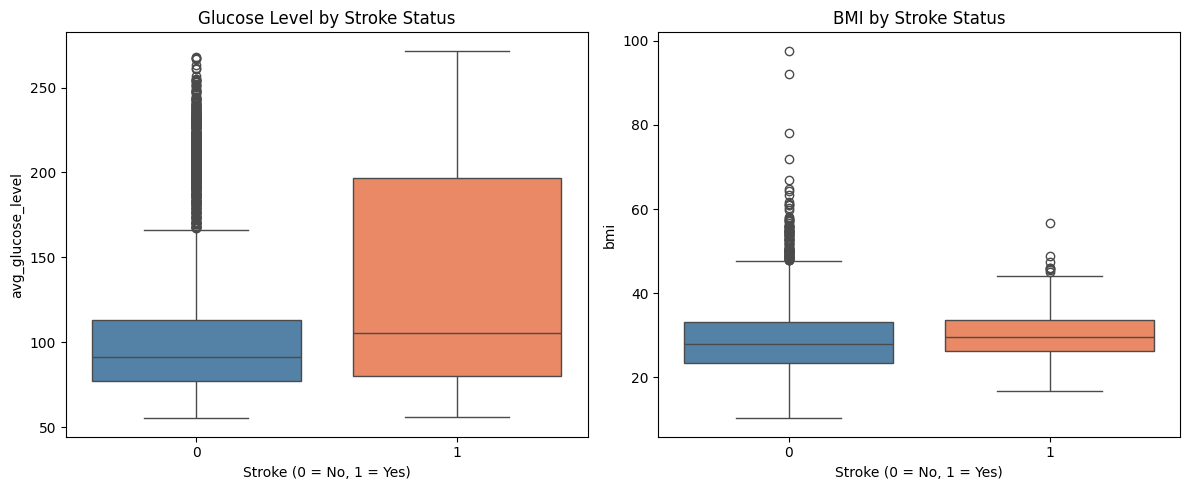

In [54]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=df,
    x="stroke",
    y="avg_glucose_level",
    hue="stroke",
    palette={0: "steelblue", 1: "coral"},
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Glucose Level by Stroke Status")
axes[0].set_xlabel("Stroke (0 = No, 1 = Yes)")

sns.boxplot(
    data=df,
    x="stroke",
    y="bmi",
    hue="stroke",
    palette={0: "steelblue", 1: "coral"},
    legend=False,
    ax=axes[1]
)
axes[1].set_title("BMI by Stroke Status")
axes[1].set_xlabel("Stroke (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()


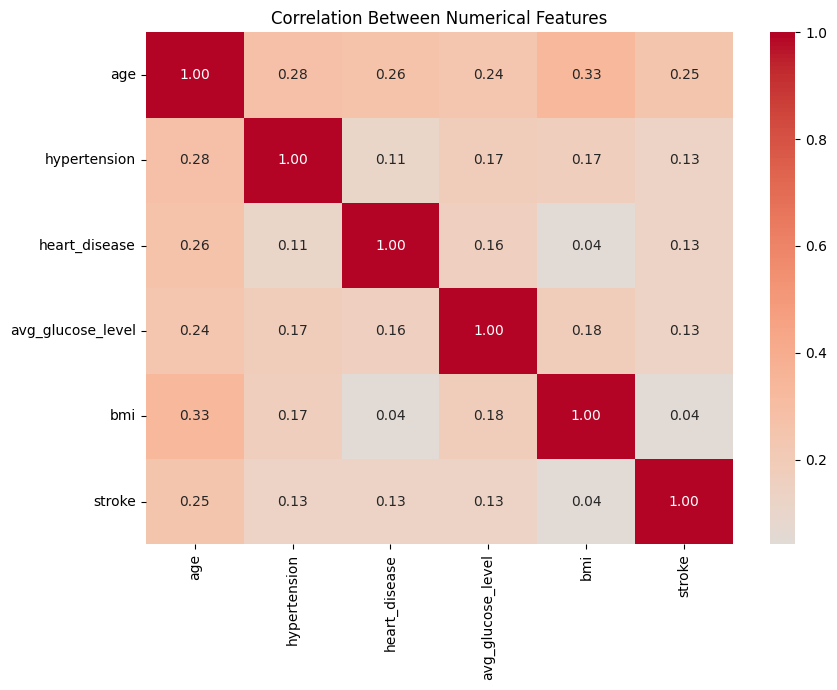

In [55]:

numeric_features = [
    "age",
    "hypertension",
    "heart_disease",
    "avg_glucose_level",
    "bmi",
    "stroke"
]

correlation = df[numeric_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


In [56]:

# Step 4.1: Separate features and target

# Remove the non-predictive record identifier
X = df.drop(columns=["id", "stroke"]).copy()

# Target variable
y = df["stroke"].copy()

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

print("\nMissing values in input features:")
print(X.isnull().sum())


Input feature shape: (5110, 10)
Target shape: (5110,)

Input features:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']

Target distribution:
stroke
0    4861
1     249
Name: count, dtype: int64

Missing values in input features:
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
dtype: int64


In [57]:

from sklearn.model_selection import train_test_split

# Split the dataset before fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting class distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))


Training feature shape: (4088, 10)
Testing feature shape: (1022, 10)

Training target shape: (4088,)
Testing target shape: (1022,)

Training class distribution:
stroke
0    3889
1     199
Name: count, dtype: int64
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64

Testing class distribution:
stroke
0    972
1     50
Name: count, dtype: int64
stroke
0    95.11
1     4.89
Name: proportion, dtype: float64


PREPROCESSING


In [58]:

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("Preprocessing libraries imported successfully.")


Preprocessing libraries imported successfully.


In [59]:

# Continuous numerical features
numeric_features = [
    "age",
    "avg_glucose_level",
    "bmi"
]

# Categorical and binary-coded features
categorical_features = [
    "gender",
    "hypertension",
    "heart_disease",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

print("Numerical features:", numeric_features)
print("Number of numerical features:", len(numeric_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

print("\nTotal input features:",
      len(numeric_features) + len(categorical_features))


Numerical features: ['age', 'avg_glucose_level', 'bmi']
Number of numerical features: 3

Categorical features: ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
Number of categorical features: 7

Total input features: 10


In [60]:

# Numerical preprocessing:
# 1. Fill missing values with the training median.
# 2. Standardize numerical measurements.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# 1. Fill any missing category with the most frequent value.
# 2. Convert categories into numerical indicator columns.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [61]:

# Learn preprocessing parameters from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same fitted transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:",
      X_train_processed.shape)

print("Testing data after preprocessing:",
      X_test_processed.shape)

print("\nMissing values remaining in training data:",
      np.isnan(X_train_processed).sum())

print("Missing values remaining in testing data:",
      np.isnan(X_test_processed).sum())

print("\nPreprocessing completed successfully.")


Training data after preprocessing: (4088, 23)
Testing data after preprocessing: (1022, 23)

Missing values remaining in training data: 0
Missing values remaining in testing data: 0

Preprocessing completed successfully.


SMOTE


In [62]:

from imblearn.over_sampling import SMOTE
from collections import Counter

# Check class distribution before SMOTE
print("Before SMOTE:", Counter(y_train))

# Apply SMOTE only to the training data
smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_processed,
    y_train
)

# Check class distribution after SMOTE
print("\nAfter SMOTE:", Counter(y_train_resampled))

print("\nOriginal training shape:", X_train_processed.shape)
print("Resampled training shape:", X_train_resampled.shape)

print("\nTest set shape (unchanged):", X_test_processed.shape)
print("Test target distribution (unchanged):")
print(y_test.value_counts())


Before SMOTE: Counter({0: 3889, 1: 199})

After SMOTE: Counter({0: 3889, 1: 3889})

Original training shape: (4088, 23)
Resampled training shape: (7778, 23)

Test set shape (unchanged): (1022, 23)
Test target distribution (unchanged):
stroke
0    972
1     50
Name: count, dtype: int64


In [63]:

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Model and evaluation libraries imported successfully.")


Model and evaluation libraries imported successfully.


In [64]:

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_resampled, y_train_resampled)

print("Random Forest training completed successfully.")


Random Forest training completed successfully.


In [65]:

xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_resampled, y_train_resampled)

print("XGBoost training completed successfully.")


XGBoost training completed successfully.


In [66]:

print("Random Forest trained:", "rf_model" in globals())
print("XGBoost trained:", "xgb_model" in globals())


Random Forest trained: True
XGBoost trained: True


In [67]:

models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)
    print(classification_report(
        y_test, y_pred,
        target_names=["No Stroke", "Stroke"],
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

results_df = pd.DataFrame(results)
print("\nMODEL COMPARISON")
display(results_df.round(4))



Random Forest
              precision    recall  f1-score   support

   No Stroke       0.95      0.96      0.96       972
      Stroke       0.12      0.10      0.11        50

    accuracy                           0.92      1022
   macro avg       0.54      0.53      0.54      1022
weighted avg       0.91      0.92      0.92      1022

Confusion matrix:
[[937  35]
 [ 45   5]]

XGBoost
              precision    recall  f1-score   support

   No Stroke       0.97      0.88      0.92       972
      Stroke       0.17      0.50      0.26        50

    accuracy                           0.86      1022
   macro avg       0.57      0.69      0.59      1022
weighted avg       0.93      0.86      0.89      1022

Confusion matrix:
[[853 119]
 [ 25  25]]

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9217,0.1250,0.1,0.1111,0.7529
1,XGBoost,0.8591,0.1736,0.5,0.2577,0.8159


In [68]:

from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Get predicted probabilities for the positive class: Stroke
xgb_probabilities = xgb_model.predict_proba(X_test_processed)[:, 1]

# Compare different prediction thresholds
for threshold in [0.5, 0.4, 0.3, 0.2, 0.1]:
    y_pred_threshold = (xgb_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred_threshold, labels=[0, 1]
    ).ravel()

    print(f"\nThreshold: {threshold}")
    print(f"True Positives (strokes detected): {tp}")
    print(f"False Negatives (strokes missed): {fn}")
    print(f"False Positives (false alarms): {fp}")
    print(f"Precision: {precision_score(y_test, y_pred_threshold, zero_division=0):.3f}")
    print(f"Recall: {recall_score(y_test, y_pred_threshold, zero_division=0):.3f}")
    print(f"F1-score: {f1_score(y_test, y_pred_threshold, zero_division=0):.3f}")



Threshold: 0.5
True Positives (strokes detected): 25
False Negatives (strokes missed): 25
False Positives (false alarms): 119
Precision: 0.174
Recall: 0.500
F1-score: 0.258

Threshold: 0.4
True Positives (strokes detected): 29
False Negatives (strokes missed): 21
False Positives (false alarms): 174
Precision: 0.143
Recall: 0.580
F1-score: 0.229

Threshold: 0.3
True Positives (strokes detected): 39
False Negatives (strokes missed): 11
False Positives (false alarms): 251
Precision: 0.134
Recall: 0.780
F1-score: 0.229

Threshold: 0.2
True Positives (strokes detected): 39
False Negatives (strokes missed): 11
False Positives (false alarms): 327
Precision: 0.107
Recall: 0.780
F1-score: 0.188

Threshold: 0.1
True Positives (strokes detected): 42
False Negatives (strokes missed): 8
False Positives (false alarms): 397
Precision: 0.096
Recall: 0.840
F1-score: 0.172


In [69]:

from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model-training rows:", X_fit.shape[0])
print("Validation rows:", X_val.shape[0])

print("\nTraining class counts:")
print(y_fit.value_counts().sort_index())

print("\nValidation class counts:")
print(y_val.value_counts().sort_index())


Model-training rows: 3270
Validation rows: 818

Training class counts:
stroke
0    3111
1     159
Name: count, dtype: int64

Validation class counts:
stroke
0    778
1     40
Name: count, dtype: int64


In [70]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from collections import Counter

# Build a fresh preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

validation_preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit preprocessing ONLY on the model-training subset
X_fit_processed = validation_preprocessor.fit_transform(X_fit)

# Transform validation data without fitting on it
X_val_processed = validation_preprocessor.transform(X_val)

print("Training features before SMOTE:", X_fit_processed.shape)
print("Validation features:", X_val_processed.shape)

print("Missing values in processed training data:",
      __import__("numpy").isnan(X_fit_processed).sum())
print("Missing values in processed validation data:",
      __import__("numpy").isnan(X_val_processed).sum())

# Apply SMOTE ONLY to the processed training subset
validation_smote = SMOTE(random_state=42)

X_fit_resampled, y_fit_resampled = validation_smote.fit_resample(
    X_fit_processed, y_fit
)

print("\nClass counts before SMOTE:", Counter(y_fit))
print("Class counts after SMOTE:", Counter(y_fit_resampled))
print("Training shape after SMOTE:", X_fit_resampled.shape)
print("Validation shape (unchanged):", X_val_processed.shape)


Training features before SMOTE: (3270, 23)
Validation features: (818, 23)
Missing values in processed training data: 0
Missing values in processed validation data: 0

Class counts before SMOTE: Counter({0: 3111, 1: 159})
Class counts after SMOTE: Counter({0: 3111, 1: 3111})
Training shape after SMOTE: (6222, 23)
Validation shape (unchanged): (818, 23)


In [71]:

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Model 1: Random Forest
rf_validation_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_validation_model.fit(X_fit_resampled, y_fit_resampled)

print("Random Forest validation model trained successfully.")

# Model 2: XGBoost
xgb_validation_model = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_validation_model.fit(X_fit_resampled, y_fit_resampled)

print("XGBoost validation model trained successfully.")


Random Forest validation model trained successfully.
XGBoost validation model trained successfully.


In [72]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

validation_models = {
    "Random Forest": rf_validation_model,
    "XGBoost": xgb_validation_model
}

validation_results = []

for model_name, model in validation_models.items():
    probabilities = model.predict_proba(X_val_processed)[:, 1]

    # Evaluate the default threshold of 0.5
    predictions = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    validation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn
    })

    print(f"\n{'=' * 35}")
    print(model_name)
    print(f"{'=' * 35}")
    print("Confusion matrix:")
    print(confusion_matrix(y_val, predictions, labels=[0, 1]))

validation_results_df = pd.DataFrame(validation_results)

print("\nVALIDATION MODEL COMPARISON")
display(validation_results_df.round(4))



Random Forest
Confusion matrix:
[[764  14]
 [ 36   4]]

XGBoost
Confusion matrix:
[[707  71]
 [ 27  13]]

VALIDATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,TP,FN,FP,TN
0,Random Forest,0.9389,0.2222,0.100,0.1379,0.7779,4,36,14,764
1,XGBoost,0.8802,0.1548,0.325,0.2097,0.8088,13,27,71,707


In [73]:

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Predict probabilities using the validation set
xgb_val_probabilities = xgb_validation_model.predict_proba(
    X_val_processed
)[:, 1]

threshold_results = []

for threshold in [0.5, 0.4, 0.3, 0.2, 0.1]:
    y_val_pred = (
        xgb_val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_val_pred, zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))


,Threshold,TP,FN,FP,TN,Precision,Recall,F1-Score
0,0.5,13,27,71,707,0.1548,0.325,0.2097
1,0.4,17,23,120,658,0.1241,0.425,0.1921
2,0.3,25,15,174,604,0.1256,0.625,0.2092
3,0.2,32,8,237,541,0.1190,0.800,0.2071
4,0.1,37,3,319,459,0.1039,0.925,0.1869


In [74]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Use the final test set that was not used for threshold selection
xgb_test_probabilities = xgb_validation_model.predict_proba(
    validation_preprocessor.transform(X_test)
)[:, 1]

# Apply the provisional threshold selected using validation data
FINAL_THRESHOLD = 0.30
xgb_test_predictions = (
    xgb_test_probabilities >= FINAL_THRESHOLD
).astype(int)

print("Final test results — XGBoost")
print("Threshold:", FINAL_THRESHOLD)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, xgb_test_predictions, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test,
    xgb_test_predictions,
    labels=[0, 1],
    target_names=["No Stroke", "Stroke"],
    zero_division=0
))

print("Accuracy:", round(
    accuracy_score(y_test, xgb_test_predictions), 4
))
print("Stroke precision:", round(
    precision_score(y_test, xgb_test_predictions, zero_division=0), 4
))
print("Stroke recall:", round(
    recall_score(y_test, xgb_test_predictions, zero_division=0), 4
))
print("Stroke F1-score:", round(
    f1_score(y_test, xgb_test_predictions, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, xgb_test_probabilities), 4
))


Final test results — XGBoost
Threshold: 0.3

Confusion matrix:
[[738 234]
 [ 14  36]]

Classification report:
              precision    recall  f1-score   support

   No Stroke       0.98      0.76      0.86       972
      Stroke       0.13      0.72      0.23        50

    accuracy                           0.76      1022
   macro avg       0.56      0.74      0.54      1022
weighted avg       0.94      0.76      0.83      1022

Accuracy: 0.7573
Stroke precision: 0.1333
Stroke recall: 0.72
Stroke F1-score: 0.225
ROC-AUC: 0.8122


In [75]:

import pandas as pd

# Get feature names created by the fitted preprocessing pipeline
feature_names = validation_preprocessor.get_feature_names_out()

# Get XGBoost feature importance scores
importance_scores = xgb_validation_model.feature_importances_

# Create a sorted feature-importance table
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
}).sort_values(by="Importance", ascending=False)

print("Top 10 most important features:")
display(feature_importance_df.head(10).round(4))


Top 10 most important features:


,Feature,Importance
0,num__age,0.2244
14,cat__work_type_Private,0.0849
21,cat__smoking_status_never smoked,0.0700
17,cat__Residence_type_Rural,0.0695
12,cat__work_type_Govt_job,0.0638
19,cat__smoking_status_Unknown,0.0561
10,cat__ever_married_No,0.0537
20,cat__smoking_status_formerly smoked,0.0529
3,cat__gender_Female,0.0495
22,cat__smoking_status_smokes,0.0493


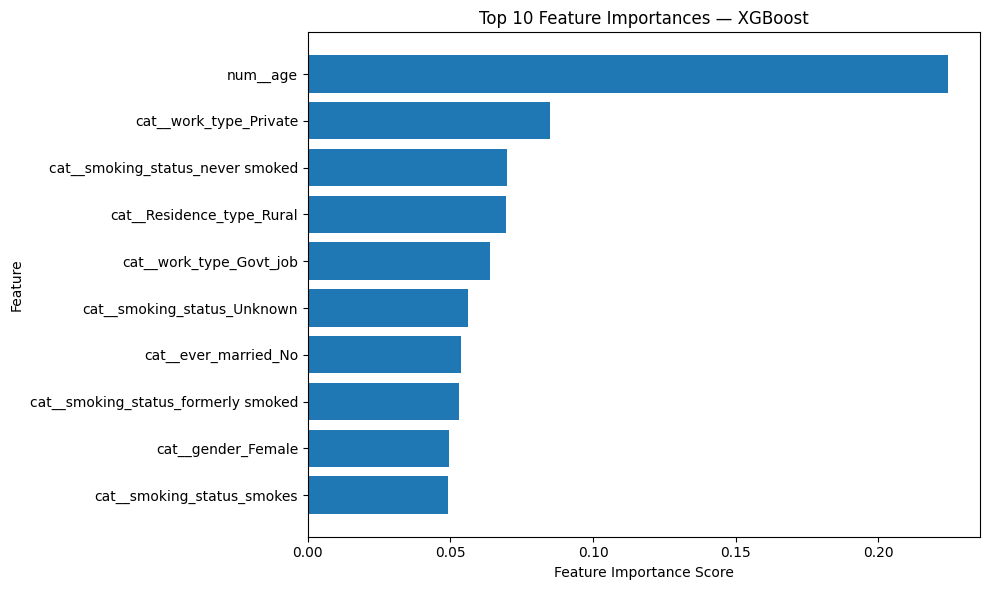

In [76]:

import matplotlib.pyplot as plt

# Select the top 10 features
top_features = feature_importance_df.head(10).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances — XGBoost")
plt.tight_layout()
plt.show()


In [77]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Use the final test predictions already calculated
tn, fp, fn, tp = confusion_matrix(
    y_test,
    xgb_test_predictions,
    labels=[0, 1]
).ravel()

error_analysis = pd.DataFrame({
    "Outcome": [
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives"
    ],
    "Meaning": [
        "Correctly predicted no stroke",
        "Predicted stroke, but actual class was no stroke",
        "Actual stroke cases missed by the model",
        "Correctly detected stroke cases"
    ],
    "Count": [tn, fp, fn, tp]
})

display(error_analysis)

print("\nTotal test cases:", len(y_test))
print("Total incorrect predictions:", fp + fn)
print("Total correctly classified cases:", tn + tp)
print("Stroke cases detected:", tp, "out of", tp + fn)
print("Stroke cases missed:", fn)


,Outcome,Meaning,Count
0,True Negatives,Correctly predicted no stroke,738
1,False Positives,"Predicted stroke, but actual class was no stroke",234
2,False Negatives,Actual stroke cases missed by the model,14
3,True Positives,Correctly detected stroke cases,36



Total test cases: 1022
Total incorrect predictions: 248
Total correctly classified cases: 774
Stroke cases detected: 36 out of 50
Stroke cases missed: 14


In [78]:

import joblib
import os

# Create a folder for project artifacts
os.makedirs("stroke_model_artifacts", exist_ok=True)

# Save the preprocessing pipeline
joblib.dump(
    validation_preprocessor,
    "stroke_model_artifacts/preprocessor.pkl"
)

# Save the XGBoost model used for final test evaluation
joblib.dump(
    xgb_validation_model,
    "stroke_model_artifacts/xgboost_model.pkl"
)

# Save the prediction threshold
joblib.dump(
    0.30,
    "stroke_model_artifacts/decision_threshold.pkl"
)

print("Saved files:")
print(os.listdir("stroke_model_artifacts"))


Saved files:
['preprocessor.pkl', 'xgboost_model.pkl', 'decision_threshold.pkl']


In [79]:

import joblib
import numpy as np

# Load all saved artifacts
loaded_preprocessor = joblib.load(
    "stroke_model_artifacts/preprocessor.pkl"
)

loaded_model = joblib.load(
    "stroke_model_artifacts/xgboost_model.pkl"
)

loaded_threshold = joblib.load(
    "stroke_model_artifacts/decision_threshold.pkl"
)

# Transform the test data with the loaded preprocessor
loaded_test_features = loaded_preprocessor.transform(X_test)

# Generate probabilities and predictions
loaded_probabilities = loaded_model.predict_proba(
    loaded_test_features
)[:, 1]

loaded_predictions = (
    loaded_probabilities >= loaded_threshold
).astype(int)

# Verify that reloaded predictions match the original ones
print("Loaded threshold:", loaded_threshold)
print("Processed test shape:", loaded_test_features.shape)
print(
    "Predictions match original:",
    np.array_equal(loaded_predictions, xgb_test_predictions)
)
print("Number of test predictions:", len(loaded_predictions))
print("Model reload verification successful.")


Loaded threshold: 0.3
Processed test shape: (1022, 23)
Predictions match original: True
Number of test predictions: 1022
Model reload verification successful.


In [80]:

import pandas as pd

def predict_stroke_risk(input_data):
    """
    Educational ML prediction only.
    This is not a clinical diagnostic tool.
    """
    input_df = pd.DataFrame([input_data])

    # Apply the saved preprocessing pipeline
    processed_input = loaded_preprocessor.transform(input_df)

    # Get estimated probability for the positive class
    probability = loaded_model.predict_proba(processed_input)[0, 1]

    # Apply the selected decision threshold
    prediction = int(probability >= loaded_threshold)

    return {
        "predicted_class": prediction,
        "predicted_label": (
            "Stroke class predicted"
            if prediction == 1
            else "No-stroke class predicted"
        ),
        "estimated_probability": round(float(probability), 4),
        "decision_threshold": loaded_threshold
    }


# Use one example from the test features
sample_input = X_test.iloc[0].to_dict()

result = predict_stroke_risk(sample_input)

print("Prediction result:")
print(result)


Prediction result:
{'predicted_class': 0, 'predicted_label': 'No-stroke class predicted', 'estimated_probability': 0.2387, 'decision_threshold': 0.3}
